In [61]:
# importing the necessary libraries for data analysis and visualization.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [62]:
# Reading the data from a csv file named "covid_19_india.csv" and "covid_vaccine_statewise.csv" .
covid_df = pd.read_csv("covid_19_india.csv")
vaccine_df = pd.read_csv("covid_vaccine_statewise.csv")

Description: Loading the data file into a Pandas DataFrame for exploration and analysis.#### 2. Load the COVID-19 Dataset

In [63]:
covid_df.head()

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1
1,2,2020-01-31,6:00 PM,Kerala,1,0,0,0,1
2,3,2020-02-01,6:00 PM,Kerala,2,0,0,0,2
3,4,2020-02-02,6:00 PM,Kerala,3,0,0,0,3
4,5,2020-02-03,6:00 PM,Kerala,3,0,0,0,3


Description: Displaying the first rows to inspect the dataset's columns and sample records

In [64]:
covid_df.drop(['Sno', 'Time', 'ConfirmedIndianNational', 'ConfirmedForeignNational'], axis = 1, inplace = True)

Description: Examine COVID-19 measures or related fields using the operation shown.

In [65]:
covid_df.head()

,Date,State/UnionTerritory,Cured,Deaths,Confirmed
0,2020-01-30,Kerala,0,0,1
1,2020-01-31,Kerala,0,0,1
2,2020-02-01,Kerala,0,0,2
3,2020-02-02,Kerala,0,0,3
4,2020-02-03,Kerala,0,0,3


Description: Displaying the first rows to inspect the dataset's columns and sample records.

In [66]:
covid_df['Active_cases'] = covid_df['Confirmed'] - (covid_df['Cured'] + covid_df['Deaths'])

Description: Examine COVID-19 measures or related fields using the operation shown

In [67]:
covid_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Date                  18110 non-null  str  
 1   State/UnionTerritory  18110 non-null  str  
 2   Cured                 18110 non-null  int64
 3   Deaths                18110 non-null  int64
 4   Confirmed             18110 non-null  int64
 5   Active_cases          18110 non-null  int64
dtypes: int64(4), str(2)
memory usage: 849.0 KB


Description: Displaying column names, data types, and non-null counts to understand the dataset structure.

In [68]:
covid_df['Date'] = pd.to_datetime(covid_df['Date'], format = '%Y-%m-%d')

Description: Converting selected columns to suitable data types for analysis.

In [69]:
# getting information about the DataFrame.
covid_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  18110 non-null  datetime64[us]
 1   State/UnionTerritory  18110 non-null  str           
 2   Cured                 18110 non-null  int64         
 3   Deaths                18110 non-null  int64         
 4   Confirmed             18110 non-null  int64         
 5   Active_cases          18110 non-null  int64         
dtypes: datetime64[us](1), int64(4), str(1)
memory usage: 849.0 KB


Description: Displaying column names, data types, and non-null counts to understand the dataset structure.

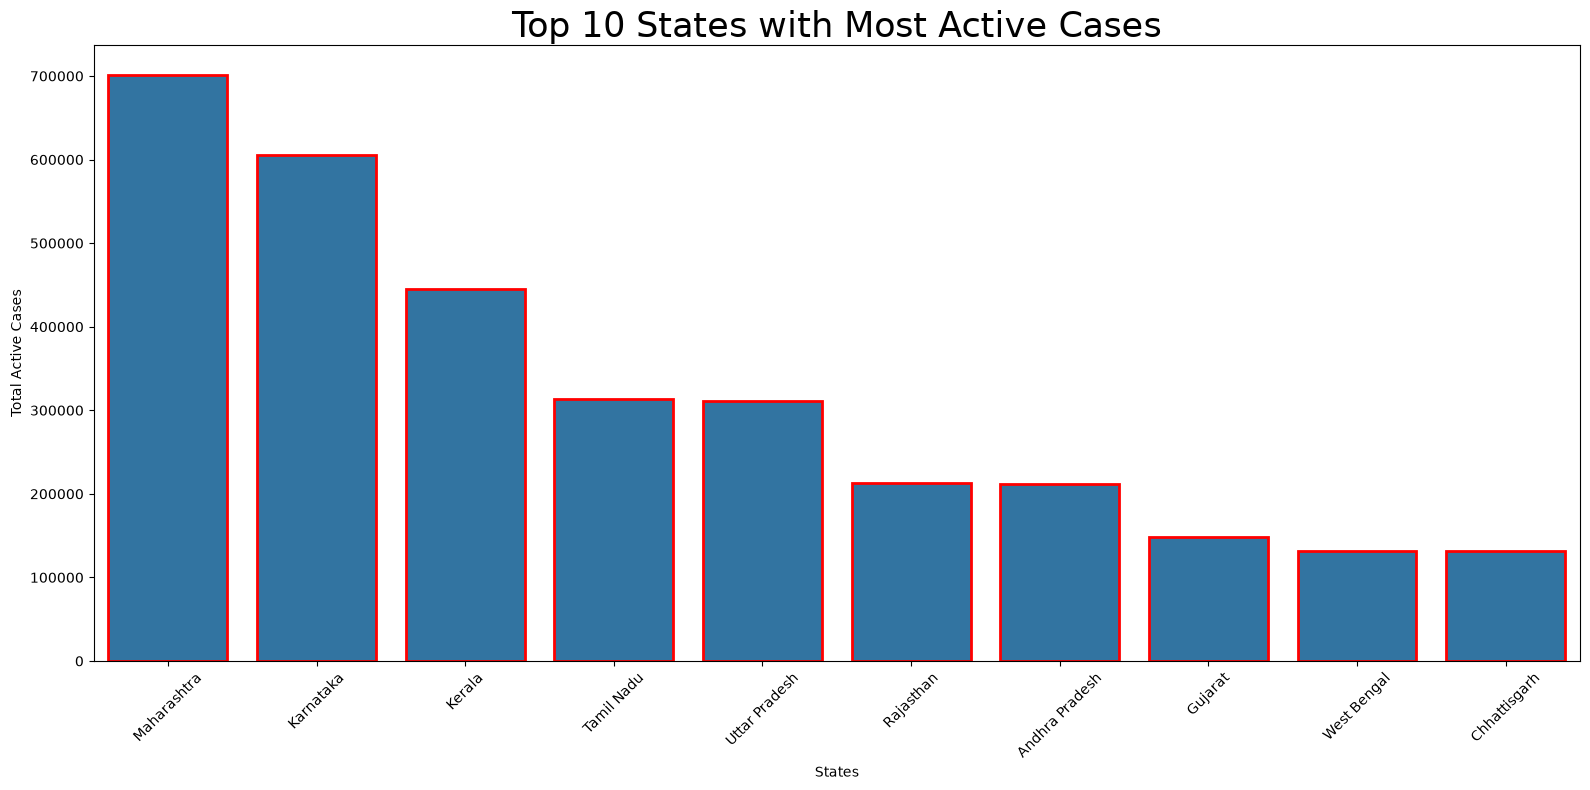

In [70]:

# Top 10 states with most active cases

top_10_active_cases = (
    covid_df.groupby('State/UnionTerritory')[['Active_cases', 'Date']]
    .max()
    .sort_values('Active_cases', ascending=False)
    .reset_index()
)

fig = plt.figure(figsize=(16, 8))

ax = sns.barplot(
    data=top_10_active_cases.iloc[:10],
    x='State/UnionTerritory',
    y='Active_cases',
    linewidth=2,
    edgecolor='red'
)

plt.title("Top 10 States with Most Active Cases", size=25)
plt.xlabel("States")
plt.ylabel("Total Active Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Description: As we can see that the maximum most Active cases in Maharashtra.

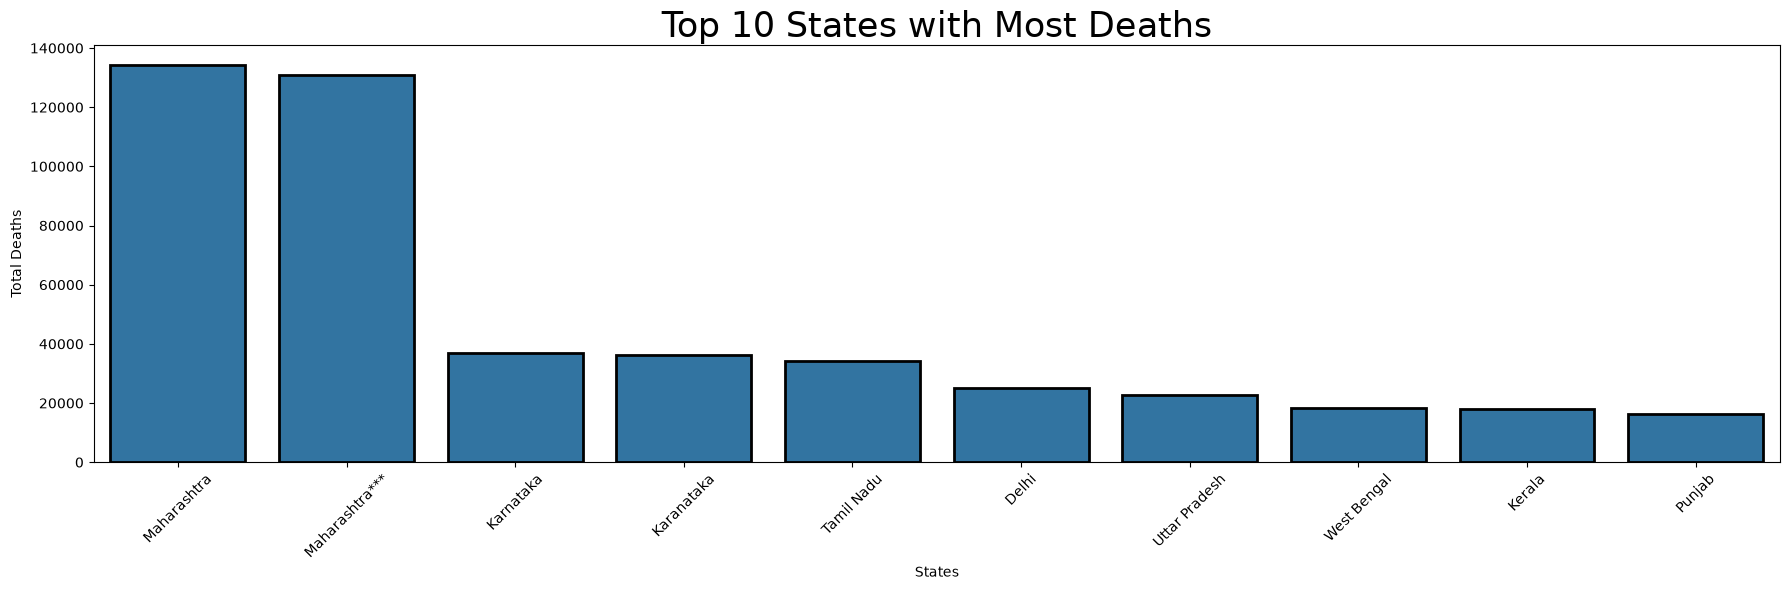

In [71]:

# Top 10 states with most deaths

top_10_deaths = (
    covid_df.groupby('State/UnionTerritory')[['Deaths', 'Date']]
    .max()
    .sort_values('Deaths', ascending=False)
    .reset_index()
)

fig = plt.figure(figsize=(18, 6))

ax = sns.barplot(
    data=top_10_deaths.iloc[:10],
    x='State/UnionTerritory',
    y='Deaths',
    linewidth=2,
    edgecolor='black'
)

plt.title("Top 10 States with Most Deaths", size=25)
plt.xlabel("States")
plt.ylabel("Total Deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Description: As we can see that the most deaths in maharashtra. 

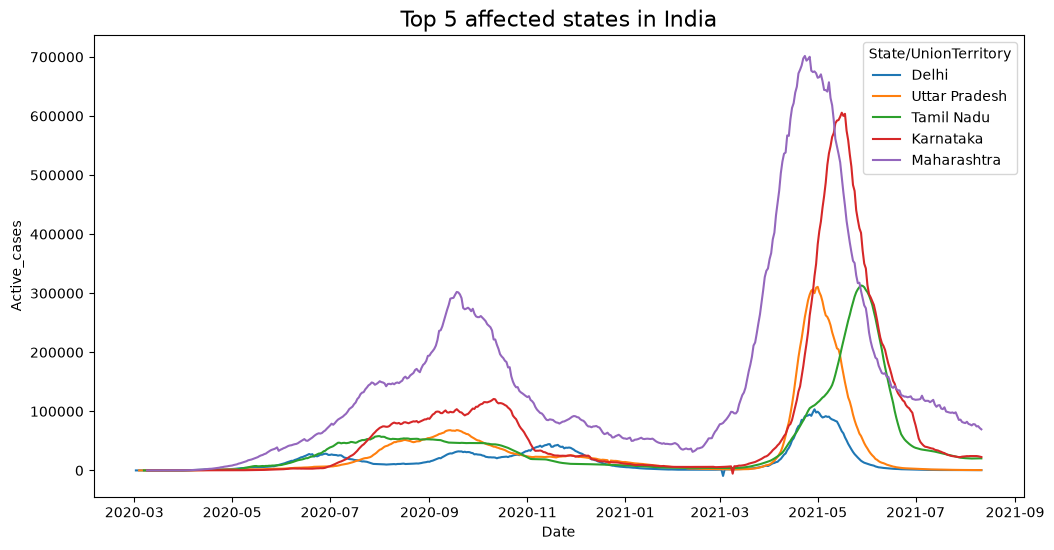

In [72]:
#Top 5 affected states in India
fig = plt.figure(figsize = (12,6))
ax = sns.lineplot(covid_df[covid_df['State/UnionTerritory'].isin(['Maharashtra', 'Karnataka', 'Tamil Nadu', 'Delhi', 'Uttar Pradesh'])], x = 'Date', y= 'Active_cases', hue = 'State/UnionTerritory')
plt.title("Top 5 affected states in India", size = 16)
plt.xlabel("Date")
plt.ylabel("Active_cases")
plt.show()

Description: As we can see that Maharashtra is the most affected state in India.

In [73]:
vaccine_df.head()

,Updated On,State,Total Doses Administered,Sessions,Sites,First Dose Administered,Second Dose Administered,Male (Doses Administered),Female (Doses Administered),Transgender (Doses Administered),...,18-44 Years (Doses Administered),45-60 Years (Doses Administered),60+ Years (Doses Administered),18-44 Years(Individuals Vaccinated),45-60 Years(Individuals Vaccinated),60+ Years(Individuals Vaccinated),Male(Individuals Vaccinated),Female(Individuals Vaccinated),Transgender(Individuals Vaccinated),Total Individuals Vaccinated
0,16/01/2021,India,48276.0,3455.0,2957.0,48276.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,23757.0,24517.0,2.0,48276.0
1,17/01/2021,India,58604.0,8532.0,4954.0,58604.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,27348.0,31252.0,4.0,58604.0
2,18/01/2021,India,99449.0,13611.0,6583.0,99449.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41361.0,58083.0,5.0,99449.0
3,19/01/2021,India,195525.0,17855.0,7951.0,195525.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,81901.0,113613.0,11.0,195525.0
4,20/01/2021,India,251280.0,25472.0,10504.0,251280.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,98111.0,153145.0,24.0,251280.0


Description: Displaying the first rows to inspect the dataset's columns and sample records.

In [74]:
#Removing Invalid State
vaccine_df = vaccine_df[vaccine_df['State'] != 'India']

In [75]:
vaccine_df.head()

,Updated On,State,Total Doses Administered,Sessions,Sites,First Dose Administered,Second Dose Administered,Male (Doses Administered),Female (Doses Administered),Transgender (Doses Administered),...,18-44 Years (Doses Administered),45-60 Years (Doses Administered),60+ Years (Doses Administered),18-44 Years(Individuals Vaccinated),45-60 Years(Individuals Vaccinated),60+ Years(Individuals Vaccinated),Male(Individuals Vaccinated),Female(Individuals Vaccinated),Transgender(Individuals Vaccinated),Total Individuals Vaccinated
212,16/01/2021,Andaman and Nicobar Islands,23.0,2.0,2.0,23.0,0.0,12.0,11.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0
213,17/01/2021,Andaman and Nicobar Islands,23.0,2.0,2.0,23.0,0.0,12.0,11.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0
214,18/01/2021,Andaman and Nicobar Islands,42.0,9.0,2.0,42.0,0.0,29.0,13.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.0
215,19/01/2021,Andaman and Nicobar Islands,89.0,12.0,2.0,89.0,0.0,53.0,36.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.0
216,20/01/2021,Andaman and Nicobar Islands,124.0,16.0,3.0,124.0,0.0,67.0,57.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,124.0


In [76]:
vaccine = vaccine_df[['Updated On', 'State', 'Male (Doses Administered)', 'Female (Doses Administered)', 'Total Individuals Vaccinated']]

In [77]:
vaccine.rename(columns = {'Updated On':'Date', 'Total Individuals Vaccinated':'Total'}, inplace = True)
vaccine.head()

,Date,State,Male (Doses Administered),Female (Doses Administered),Total
212,16/01/2021,Andaman and Nicobar Islands,12.0,11.0,23.0
213,17/01/2021,Andaman and Nicobar Islands,12.0,11.0,23.0
214,18/01/2021,Andaman and Nicobar Islands,29.0,13.0,42.0
215,19/01/2021,Andaman and Nicobar Islands,53.0,36.0,89.0
216,20/01/2021,Andaman and Nicobar Islands,67.0,57.0,124.0


In [78]:
males = vaccine['Male (Doses Administered)'].sum()
females = vaccine['Female (Doses Administered)'].sum()

In [79]:
#Males vs Females vaccinated
px.pie(names = ['males', 'females'], values = [males, females], title = 'Males vs Females vaccinated')

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'domain': {'x': [0.0, 1.0], 'y': [0.0, 1.0]},
              'hovertemplate': 'label=%{label}<br>value=%{value}<extra></extra>',
              'labels': array(['males', 'females'], dtype=object),
              'legendgroup': '',
              'name': '',
              'showlegend': True,
              'type': 'pie',
              'values': {'bdata': 'AABID+TMD0IAAAj6m+YLQg==', 'dtype': 'f8'}}],
    'layout': {'legend': {'tracegroupgap': 0}, 'template': '...', 'title': {'text': 'Males vs Females vaccinated'}}
})

Description: As we can see that almost 53.3% of males are vaccinated and 46.7% of females are vaccinated.

C:\Users\NOBODY\AppData\Local\Temp\ipykernel_8920\134765216.py:2: FutureWarning:

Indexing with multiple keys (implicitly converted to a tuple of keys) will be deprecated, use a list instead.



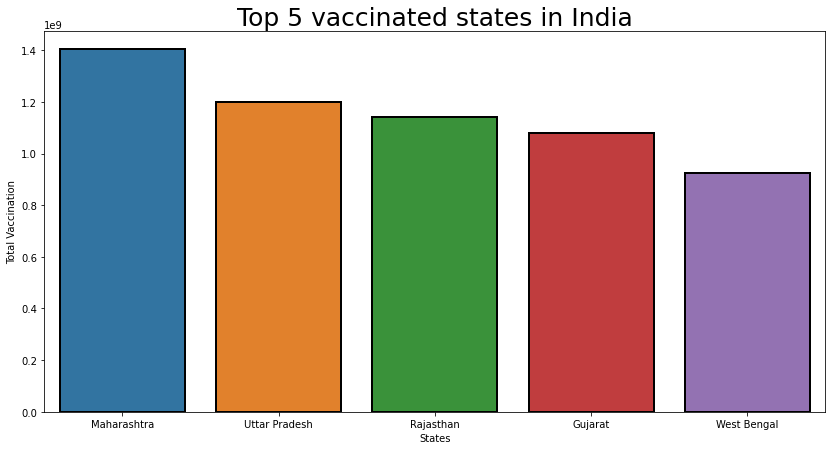

In [ ]:
#Top 5 vaccinated states in India
top_5_vac_states = vaccine.groupby('State')['Total', 'Date'].sum().sort_values('Total', ascending = False).reset_index()
fig = plt.figure(figsize = (14,7))
ax = sns.barplot(top_5_vac_states[:5], x = 'State', y = 'Total', linewidth = 2, edgecolor = 'black')
plt.title("Top 5 vaccinated states in India", size = 25)
plt.xlabel("States")
plt.ylabel("Total Vaccination")
plt.show()

Description: As we can see that Maharashtra is the most vaccinated state in India.

C:\Users\NOBODY\AppData\Local\Temp\ipykernel_8920\2113886462.py:2: FutureWarning:

Indexing with multiple keys (implicitly converted to a tuple of keys) will be deprecated, use a list instead.



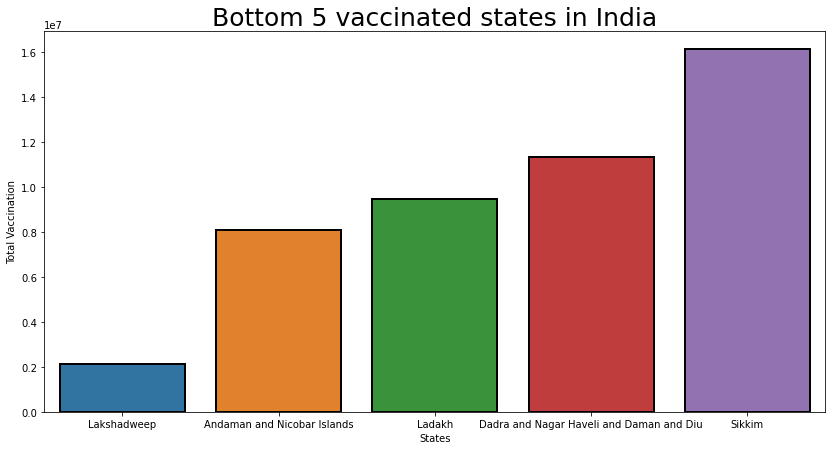

In [ ]:
#Bottom 5 vaccinated states in India
bottom_5_vac_states = vaccine.groupby('State')['Total', 'Date'].sum().sort_values('Total', ascending = True).reset_index()
fig = plt.figure(figsize = (14,7))
ax = sns.barplot(bottom_5_vac_states[:5], x = 'State', y = 'Total', linewidth = 2, edgecolor = 'black')
plt.title("Bottom 5 vaccinated states in India", size = 25)
plt.xlabel("States")
plt.ylabel("Total Vaccination")
plt.show()

Description: As we can see that sikkim is the least vaccinated state in India 